In [1]:
import sys
sys.path.append('../Utils')
sys.path.append('../Data')
sys.path.insert(0, '../../FRLC/src/')

from objective import solve_V_all_slices
from simulations import create_realistic_data, visualize_all
from plot_utils import plot_slices_horizontal_centered, plot_mass_transport_heatmap, plot_gene_panels, panel
from impute import impute_slice_fgw_barycenter, align_by_pca
from metrics import cluster_compute_ari_and_plot
from prepare_zesta import prepare_data
import re

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import minimize_scalar

# import torch

import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import torch
torch.use_deterministic_algorithms(True)

if torch.cuda.is_available():
    from objective_cuda import solve_V_all_slices_torch as solve_V_all_slices
else:
    from objective import solve_V_all_slices


%load_ext autoreload
%autoreload 2

# Load data. 

Change fname according to local directories. Both scRNA and spatial data can be downloaded from:
https://db.cngb.org/stomics/zesta/download/

The resulting adata_insamp is a list of adata objects containing spatial transcriptomics. pd_B is the reference matrix representing mean expression for cell types. 

In [2]:
adata_insamp, pd_B = prepare_data(threshold=1.25, return_sc=False, data_dir = '../../../Data/ZESTA/')

../../../Data/ZESTA/


/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_zesta.py:67: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  zf3.X = zf3.layers["counts"].copy()
/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_zesta.py:71: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  zf5.X = zf5.layers["counts"].copy()
/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_zesta.py:75: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  zf10.X = zf10.layers["counts"].copy()
/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_zesta.py:79: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  zf12.X = zf12.layers["counts"].copy()
/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_zesta.py:83: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  zf18.X = zf18.layers["counts"].copy()
/home/zhaow/ST-CARD/GitRepo/Scripts/../

# Run ATLIS. 

In [3]:
time = [3,5,10,12,18,24]

In [4]:
torch.manual_seed(0); torch.cuda.manual_seed_all(0)
# V1, pi1, aux = solve_V_all_slices(
#                         adata_insamp, pd_B, #time=time,
#                         lam=1e5, mu=1e1, 
#                         verbose=True,
#                         ot_solver='low_rank',
#                         alpha = 0.5
#                     )

# torch.manual_seed(0); torch.cuda.manual_seed_all(0)
# V2, pi2, aux = solve_V_all_slices(
#                         adata_insamp, pd_B, #time=time,
#                         lam=1e5, mu=1e1, 
#                         verbose=True,
#                         ot_solver='low_rank',
#                         alpha = 0.5
#                     )

# print(max(np.abs(a - b).max() for a, b in zip(V1, V2)))
# print("pi:", max(np.abs(a.toarray() - b.toarray()).max()
#                  for a, b in zip(pi1, pi2)))
V, pi, aux = solve_V_all_slices(
                        adata_insamp, pd_B, #time=time,
                        lam=1e5, mu=1e1, 
                        verbose=True,
                        ot_solver='low_rank',
                        alpha = 0.5
                    )

iter    0  f=2.269080e+08  rel_drop=9.757e-01  mean step=9.73e-07
iter   50  f=1.027297e+06  rel_drop=2.472e-04  mean step=1.24e-07
iter  100  f=1.021944e+06  rel_drop=1.576e-05  mean step=9.17e-08
iter  106  f=1.021871e+06  rel_drop=9.705e-06  mean step=9.04e-08
stopped after iteration # 106
iter    0  f=1.091367e+08  rel_drop=9.759e-01  mean step=9.72e-07
iter   50  f=2.121700e+05  rel_drop=7.678e-05  mean step=5.62e-07
iter  100  f=2.118189e+05  rel_drop=1.589e-05  mean step=4.93e-07
iter  124  f=2.117557e+05  rel_drop=9.828e-06  mean step=4.76e-07
stopped after iteration # 124
iter    0  f=2.019017e+08  rel_drop=9.757e-01  mean step=9.74e-07
iter   50  f=2.784564e+05  rel_drop=2.230e-04  mean step=4.47e-07
iter  100  f=2.769501e+05  rel_drop=5.712e-05  mean step=3.77e-07
iter  150  f=2.763903e+05  rel_drop=2.942e-05  mean step=3.46e-07
iter  200  f=2.760939e+05  rel_drop=1.465e-05  mean step=3.27e-07
iter  223  f=2.760173e+05  rel_drop=9.977e-06  mean step=3.21e-07
stopped after it

In [5]:


import matplotlib.pyplot as plt
ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
            np.vstack(V),
            ad.concat(adata_insamp),
            celltype_key="bin_annotation",
            embedding_key="spatial",
            clustering="leiden",
            plot=False,
            auto_resolution=True,
            # resolution_grid=np.linspace(0.01,2,50),

)

n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_insamp])
for i, adt in enumerate(adata_insamp):
    adt.obs['pred_label'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

print('ari='+str(ari))
print('nmi='+str(nmi))



/home/zhaow/ST-CARD/GitRepo/Scripts/../Utils/metrics.py:20: UserWarning: You’re trying to run this on 59 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  sc.pp.neighbors(tmp, n_neighbors=n_neighbors, use_rep=None, random_state=random_state)
/home/zhaow/ST-CARD/GitRepo/Scripts/../Utils/metrics.py:26: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(tmp, resolution=resolution, key_added=key, random_state=random_state)
/home/zhaow/ST-CARD/GitRepo/Scripts/../Utils/metrics.py:20: UserWarning: You’re trying to run this on 59 dimensions 

Leiden: target_k=45, best_resolution=0.969, n_clusters=45
ari=0.31850205953891725
nmi=0.6563681021397877


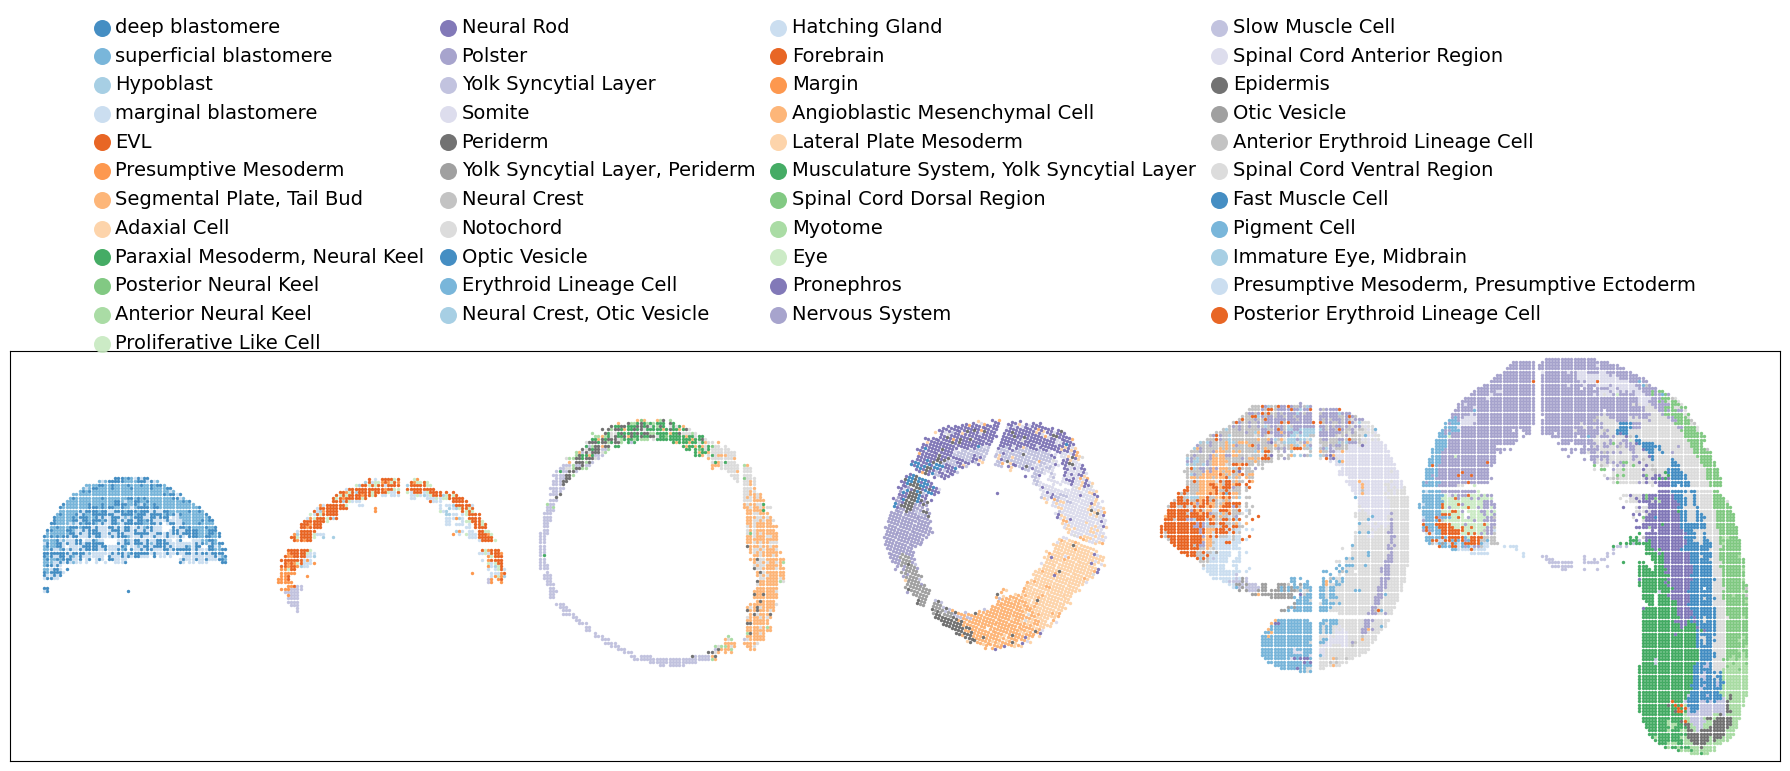

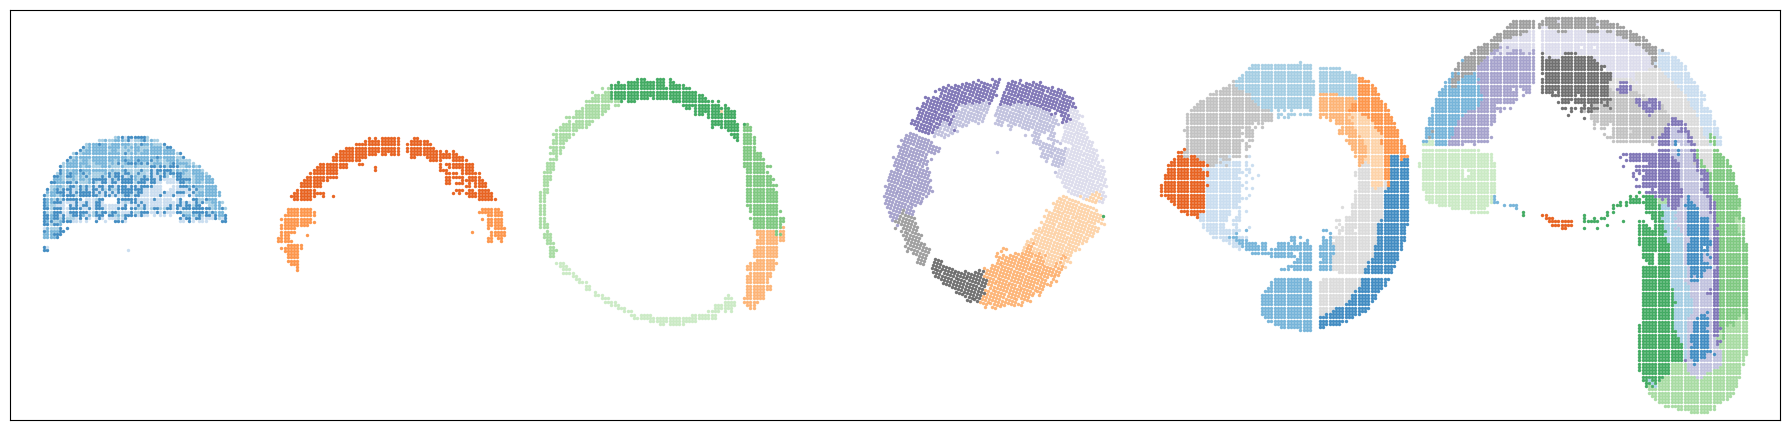

In [6]:
cmap = 'tab20c'
fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_insamp,
    obs_key="bin_annotation",
    coord_keys=("x", "y"),      # uses ad.obs['x'], ad.obs['y'] if present
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    order_key=None,     # optional; requires each slice has exactly one time_point
    # order_map={"E10.5": 10.5, "E11.5": 11.5},  # optional helper
    y_scale=1.0,
    x_gap = 350,
    s=6,
    legend_loc='upper center',
    legend_bbox=(0.5,1.41),
    legend_ncol = 4,
    legend_font=14,
    truth_cmap=cmap,
    truth_key='pred_label'
)

cmap = 'tab20c'
fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_insamp,
    obs_key="pred_label",
    coord_keys=("x", "y"),      # uses ad.obs['x'], ad.obs['y'] if present
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    order_key=None,     # optional; requires each slice has exactly one time_point
    # order_map={"E10.5": 10.5, "E11.5": 11.5},  # optional helper
    legend=False,
    y_scale=1.0,
    x_gap = 350,
    s=6,
    truth_cmap=cmap,
    truth_key='pred_label'
)

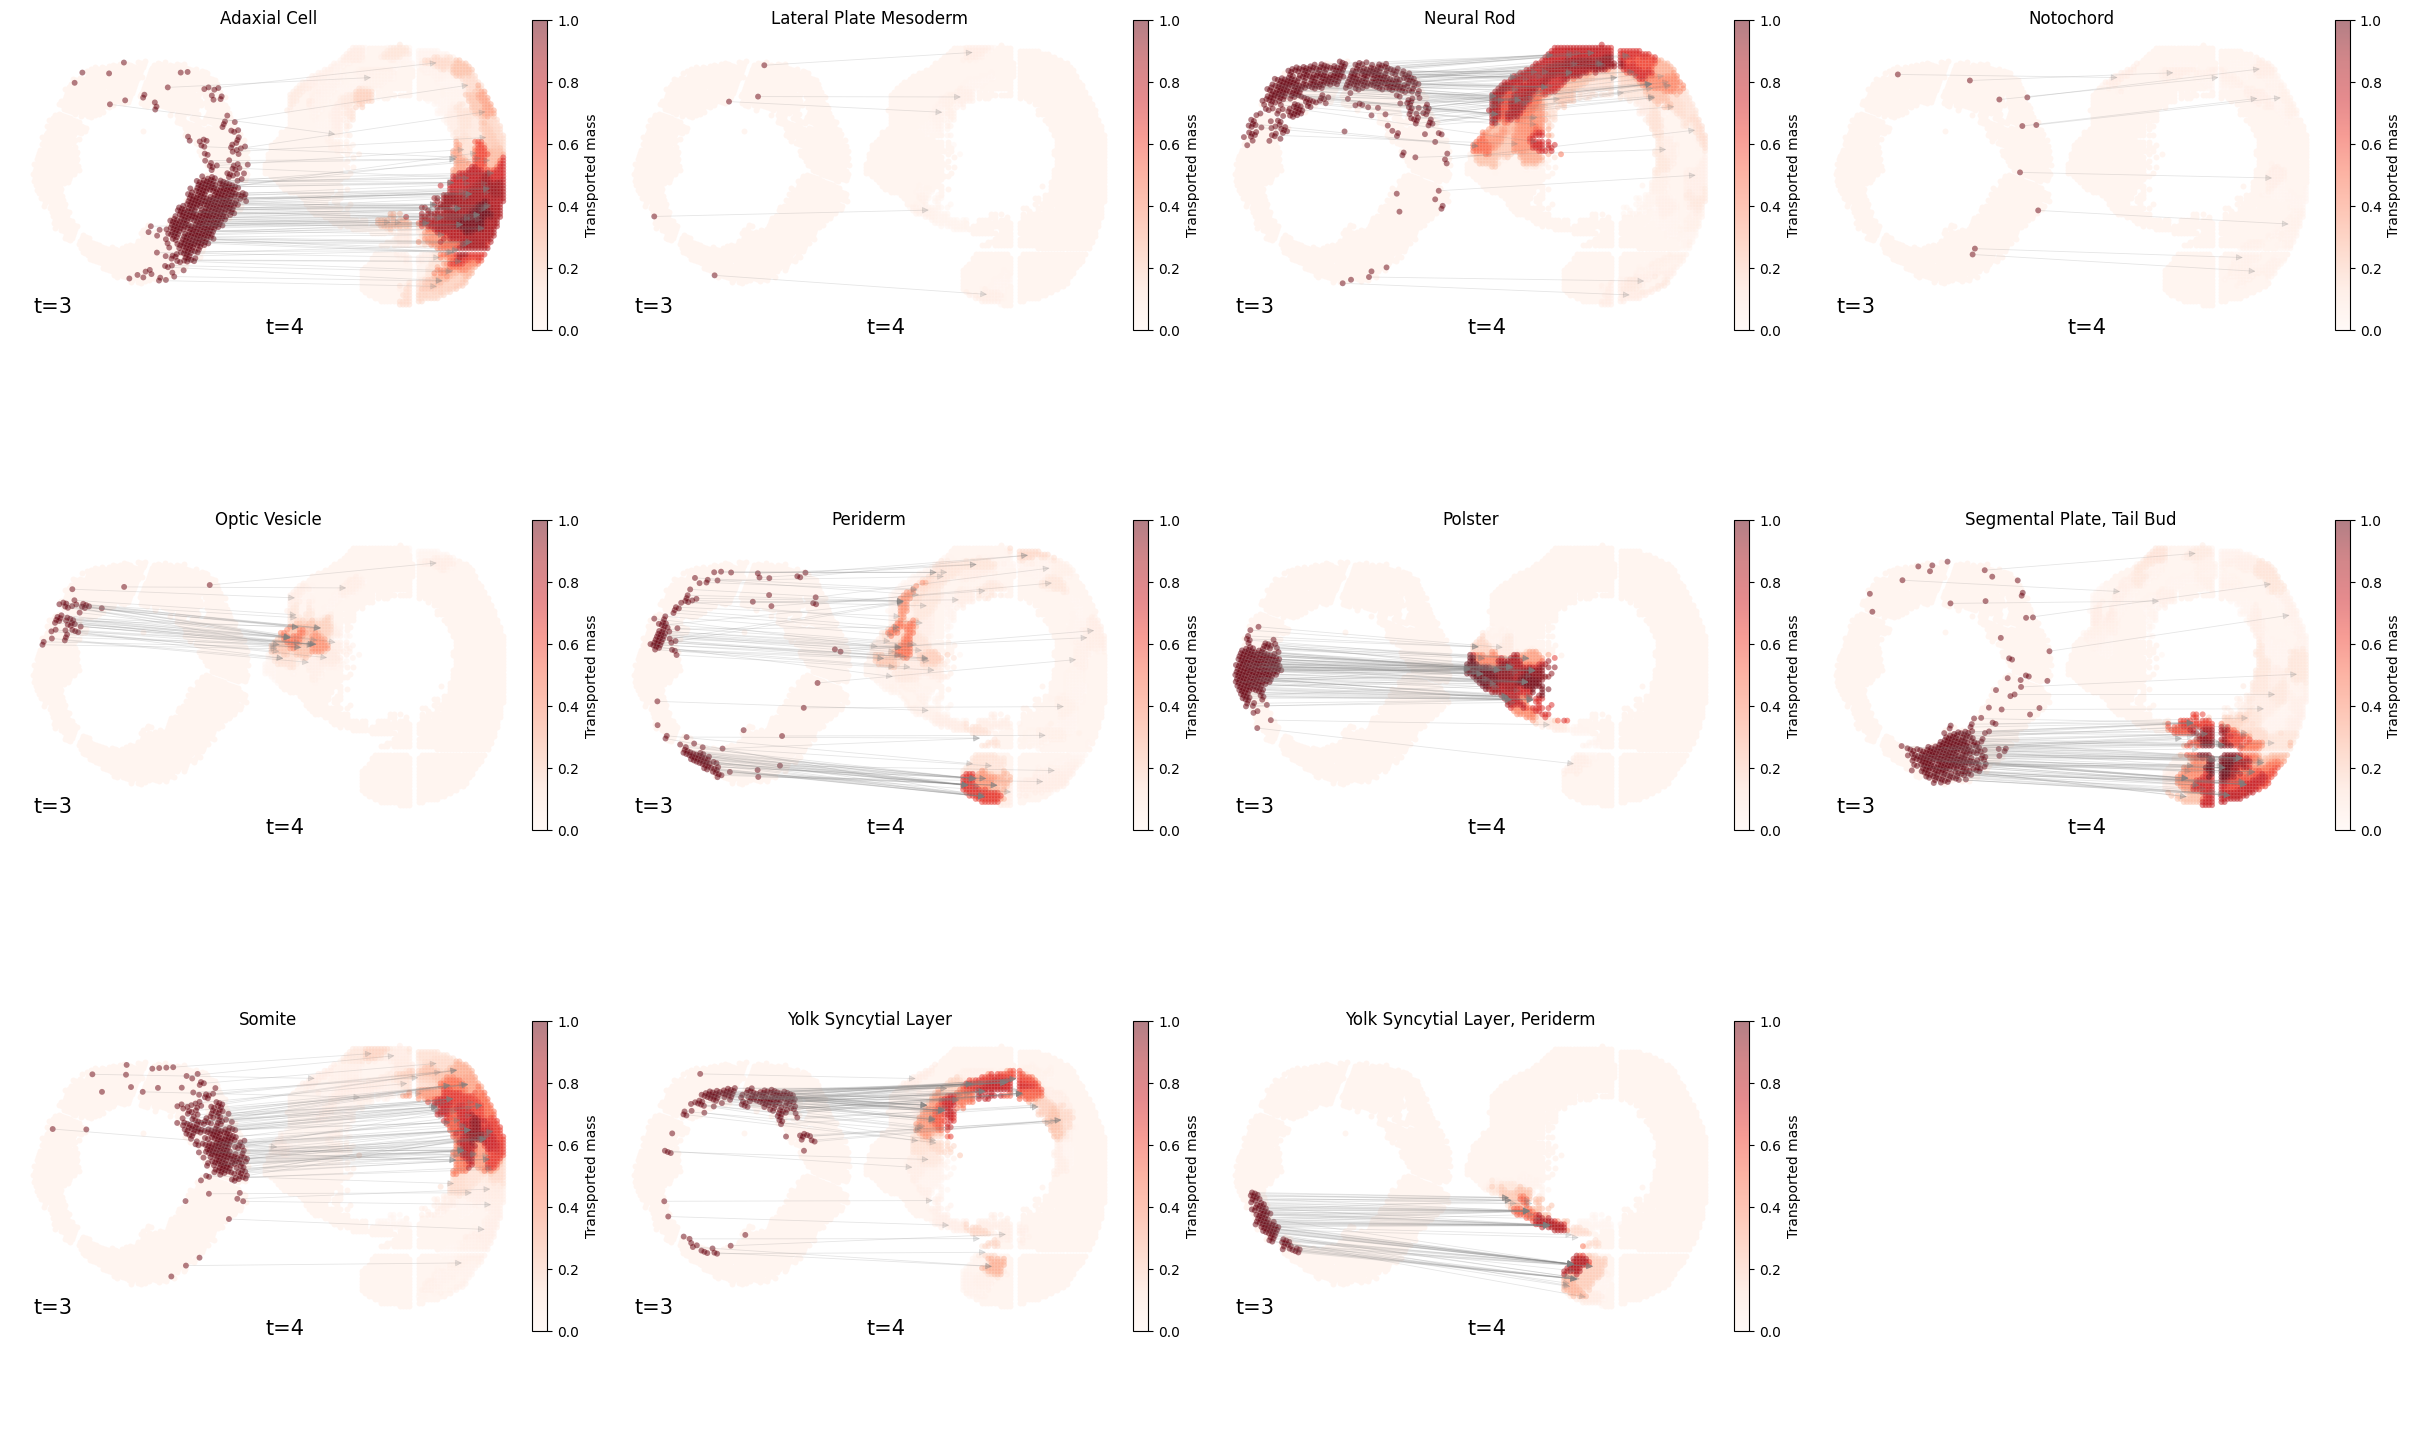

In [7]:
import math
cell_types = list(adata_insamp[3].obs["bin_annotation"].unique())
cell_types = sorted(cell_types)   
n = len(cell_types)

ncols = 4                         
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(6 * ncols, 5 * nrows),   
    constrained_layout=True
)
axes = np.asarray(axes).reshape(-1)

pi_dense = [p.toarray() if sp.issparse(p) else np.asarray(p) for p in pi]



for i, cell_type in enumerate(cell_types):
    ax = axes[i]

    
    fig_i, ax_i, masses = plot_mass_transport_heatmap(
        adata_insamp,
        V,
        pi_dense,
        t_start=3,
        t_end=4,
        source_celltype=cell_type,
        celltype_obs_key="bin_annotation",
        source_mass_source="obs",
        y_gap=1200,
        y_scale=1.0,
        show_edges=True,
        n_sources_show = 100,
        alpha=0.5,
        cmap="Reds",
        edge_alpha=0.2,
        ax=ax,         
        fig=fig,       
       
    )

    ax.set_title(str(cell_type), fontsize=12)


for j in range(n, len(axes)):
    axes[j].axis("off")

# Now try an interpolation between 4th-6th slices

In [14]:
n_time = 3

def norm_rows(V):
    V = np.asarray(V)
    row_sum = V.sum(axis=1, keepdims=True)
    return V / np.where(row_sum == 0, 1.0, row_sum)

X1 = np.vstack([adata_insamp[-1].obs['x'], adata_insamp[-1].obs['y']]).T
X0 = np.vstack([adata_insamp[-3].obs['x'],  adata_insamp[-3].obs['y']]).T
Y1 = norm_rows(V[-1])
Y0 = norm_rows(V[-3])

X_aligned_list = []
X_true_list    = []
Y_bar_list     = []
Y_true_list    = []

X_true = np.vstack([adata_insamp[-1].obs['x'], adata_insamp[-1].obs['y']]).T
for i in range(3):
    print(i)
    X_bar, Y_bar, C_bar, log = impute_slice_fgw_barycenter(
        X0, Y0, X1, Y1,
        t=0.25 * (i + 1),
        N_bary=1000,
        alpha=0.5,
        random_state=42,
        n_input=1000
    )
    # X_true        = np.vstack([adata_insamp[i+1].obs['x'], adata_insamp[i+1].obs['y']]).T
    X_bar_aligned = align_by_pca(X_bar, X_true)

    X_aligned_list.append(X_bar_aligned)
    # X_true_list.append(X_true)
    Y_bar_list.append(norm_rows(Y_bar))   # normalized
    # Y_true_list.append(norm_rows(V_true_temporal[i+1]))

0
1
2


# To inspect a specific gene:

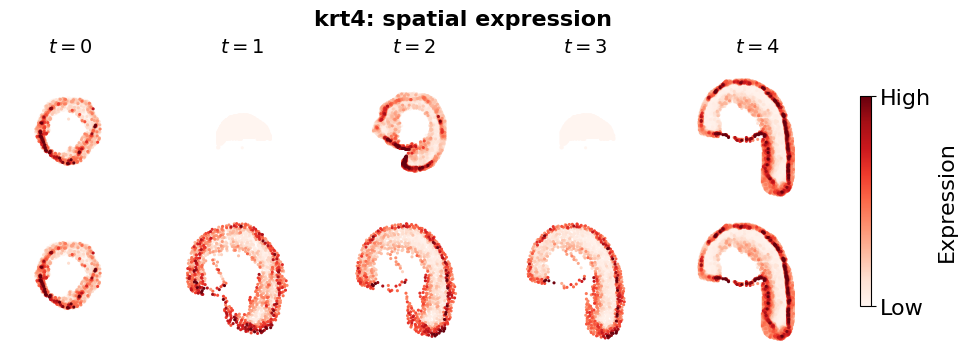

In [15]:
gene = 'krt4'

def blank(like):
    """Empty panel with the same coords as another, for padding a short row."""
    X, _ = like
    return X, np.zeros(len(X))


truth = [
    panel(adata_insamp[-3], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[-2], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[-1], gene),
]
atlis = [panel(Y, gene, coords=X, basis=pd_B)
         for Y, X in zip(Y_bar_list, X_aligned_list)]

rows = {
    "Truth": truth,
    "ATLIS": [truth[0]] + atlis + [truth[-1]],
}
fig=plot_gene_panels(gene, rows, color_mode="panel", cmap='Reds')

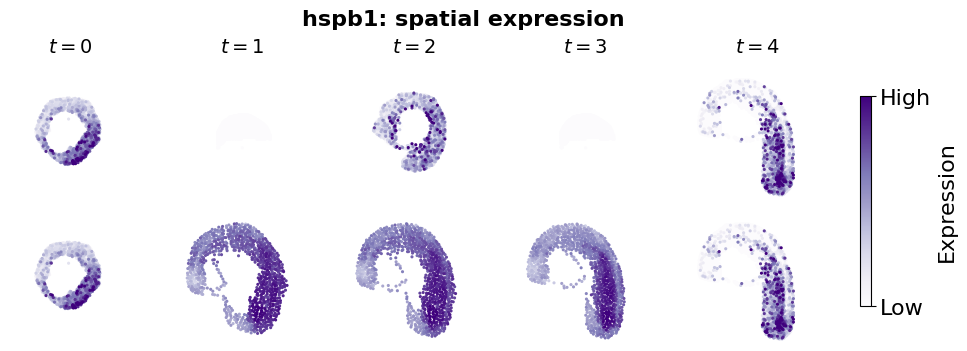

In [16]:
gene = 'hspb1'

def blank(like):
    """Empty panel with the same coords as another, for padding a short row."""
    X, _ = like
    return X, np.zeros(len(X))


truth = [
    panel(adata_insamp[-3], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[-2], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[-1], gene),
]
atlis = [panel(Y, gene, coords=X, basis=pd_B)
         for Y, X in zip(Y_bar_list, X_aligned_list)]

rows = {
    "Truth": truth,
    "ATLIS": [truth[0]] + atlis + [truth[-1]],
}
fig=plot_gene_panels(gene, rows, color_mode="panel", cmap='Purples')

# Next, we use the annotation from ATLIS to analyze the change in cell type programs across time points

In [22]:
from downstream import analyze_cluster_dynamics
cluster_time_df, cluster_celltype_df, cluster_label_df, cluster_time_counts, cluster_markers = analyze_cluster_dynamics(
    adata_insamp,
    V,
    pd_B,
    cluster_key="pred_label",
    time_key="time_point")

/tmp/ipykernel_2011723/3505544713.py:46: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


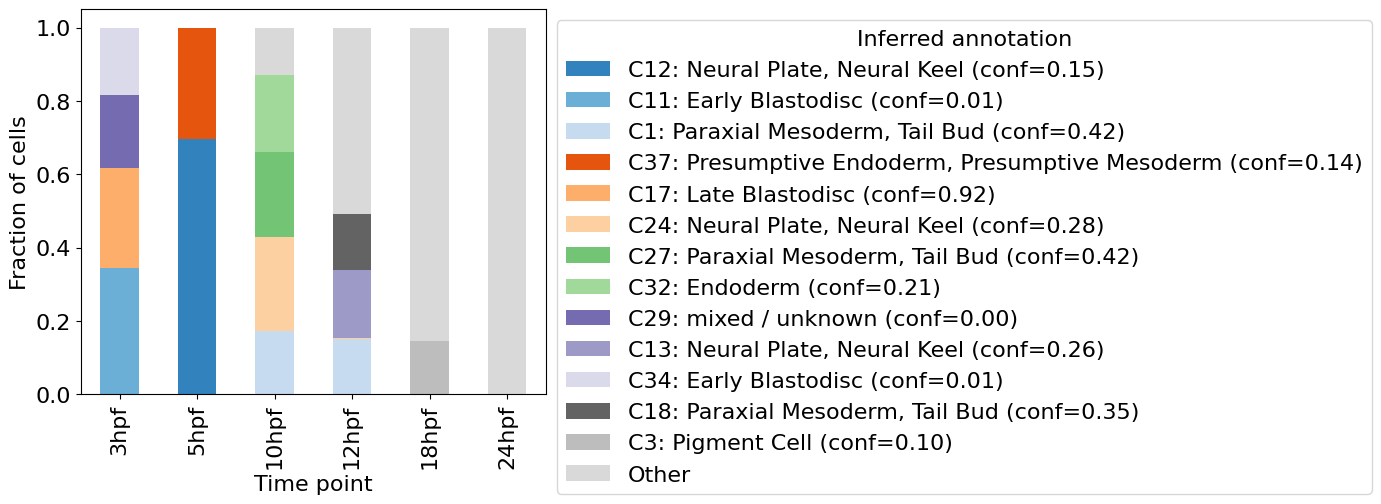

In [23]:
import matplotlib.pyplot as plt

def sort_hpf_index(df):
    idx = df.index.astype(str)
    nums = idx.str.replace("hpf", "", regex=False).astype(float)
    return df.iloc[np.argsort(nums)]

def extract_cluster_id(colname):
    m = re.match(r"(C\d+)", colname)
    if m is None:
        return None
    return m.group(1)
    
cluster_to_label = {
    row.cluster: f"C{row.cluster}: {row.label} (conf={row.confidence:.2f})"
    for _, row in cluster_label_df.iterrows()
}

plot_df = cluster_time_counts.T.rename(columns=cluster_to_label)
plot_df = sort_hpf_index(plot_df)                               # IMPORTANT
plot_df = plot_df.div(plot_df.sum(axis=1), axis=0)              # fractions

K = 13
top_types = plot_df.mean(axis=0).sort_values(ascending=False).head(K).index
plot_df["Other"] = plot_df.drop(columns=top_types).sum(axis=1)
plot_df = plot_df[top_types.tolist() + ["Other"]]



def extract_cluster_index(col):
    m = re.match(r"C(\d+)", col)
    return int(m.group(1)) if m else None


def sort_hpf_index(df):
    idx = df.index.astype(str)
    nums = idx.str.replace("hpf", "", regex=False).astype(float)
    return df.iloc[np.argsort(nums)]

plt.rcParams['figure.figsize'] = (6, 5)
plt.rcParams['font.size'] = 16
ax = plot_df.plot(kind="bar", stacked=True, cmap='tab20c')# color=colors)
ax.set_ylabel("Fraction of cells")                              # FIX
ax.set_xlabel("Time point")
ax.legend(title="Inferred annotation", bbox_to_anchor=(1.0, 1), loc="upper left")
plt.tight_layout()
# plt.savefig('../Figures/ZESTA/inferred_clusters.png',bbox_inches='tight')
plt.show()

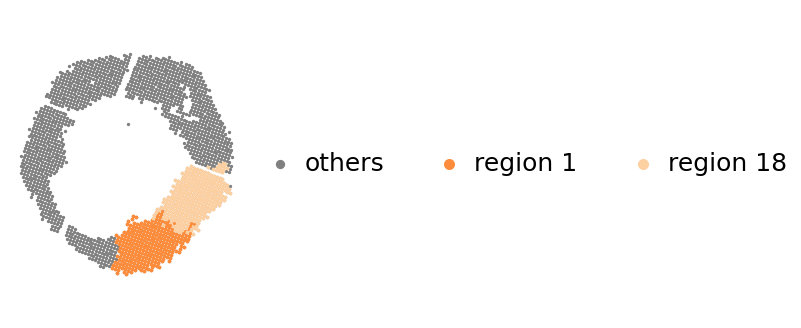

In [24]:
plt.rcParams['figure.figsize'] = (3,4)
cmap = plt.get_cmap("tab20c")
# colors = cmap(np.linspace(0, 11/20, 20))
tab20c = plt.get_cmap("tab20c").colors
t = 3
plt.scatter(adata_insamp[t].obs['x'], adata_insamp[t].obs['y'], c='gray', s=2, label='others')
plt.scatter(adata_insamp[t][adata_insamp[t].obs["pred_label"] == 1].obs['x'], adata_insamp[t][adata_insamp[t].obs["pred_label"] == 1].obs['y'], s=3,  color=tab20c[5], label='region 1')
plt.scatter(adata_insamp[t][adata_insamp[t].obs["pred_label"] == 18].obs['x'], adata_insamp[t][adata_insamp[t].obs["pred_label"] == 18].obs['y'], s=3,  color=tab20c[7],  label='region 18')

plt.axis('equal')
plt.axis('off')
plt.legend(
        frameon=False,
        fontsize=18,
        markerscale=4,      # makes legend dots larger
        handlelength=1.2,
        handletextpad=0.4,
        borderpad=0.2,
        labelspacing=0.5,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=3
)
plt.show()

/home/zhaow/miniforge3/lib/python3.13/site-packages/scanpy/plotting/_anndata.py:965: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


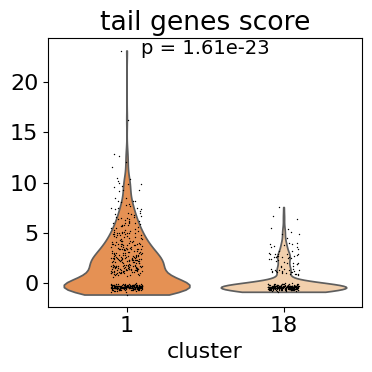

In [26]:
tail = ['tbxta', 'fgf8a', 'eve1', 'tbx16', 'bmp4', 'cyp26a1',
 'foxd3', 'dlc', 'snai1a', 'tbx16l']

adata_cat = ad.concat(adata_insamp)

sc.tl.score_genes(adata_cat, tail, score_name="tail_score")
sub = adata_cat[adata_cat.obs["pred_label"].isin([1,18])].copy()


fig, axes = plt.subplots(1,1, figsize=(4,4), sharey=False)

plt.rcParams['font.size'] = 16
sc.pl.violin(
    sub,
    keys="tail_score",
    groupby="pred_label",
    stripplot=True,
    ax=axes,
    show=False,
    palette=[tab20c[5], tab20c[7]], 
)

from scipy.stats import mannwhitneyu

x1  = adata_cat.obs.loc[adata_cat.obs["pred_label"] == 1,  "tail_score"]
x18 = adata_cat.obs.loc[adata_cat.obs["pred_label"] == 18, "tail_score"]

_, pval = mannwhitneyu(x1, x18, alternative="two-sided")
ymin, ymax = axes.get_ylim()
y = ymax - 0.08 * (ymax - ymin)

# axes.plot([0, 1], [y, y], lw=1.2, c="black")
axes.text(
    0.5,
    y + 0.005 * (ymax - ymin),
    f"p = {pval:.2e}",
    ha="center",
    va="bottom",
    fontsize=14,
)

axes.set_title('tail genes score')
axes.set_ylabel('')
plt.xlabel('cluster', fontsize=16)

plt.tight_layout()

# plt.savefig("../Figures/ZESTA/cluster_diff_marker.png", dpi=300, bbox_inches="tight")
plt.show()